# The Pipeline. 

Take your time to understand this file as its what runs the whole show

In [3]:
from src.segmentation_pipeline import segmentation_pipeline
from src.model_run import start_prediction_machine, detectron2_instances
from src.classic_instances import instance_regions, make_instance_gif
from src.fusion import *
from src.classifier import classify_instances, load_classifiers, Category_Classifier
from src.coco_json_functions import *
from src.model_run import CLASSES
# from src.instance_based_evaluation import compare_coco
from tqdm import tqdm

from collections import defaultdict
import cv2
import numpy as np
from matplotlib import pyplot as plt

import imagesize
from pathlib import Path


from sklearn.base import TransformerMixin, BaseEstimator
class SelectColumns(BaseEstimator, TransformerMixin):
    def __init__(self, columns):
        self.columns = columns
    def fit(self, xs, ys, **params):
        return self
    def transform(self, xs):
        return xs[self.columns]
    
from pathlib import Path

ModuleNotFoundError: No module named 'detectron2.engine'

In [8]:
# Config
####################################################################################################
# INPUT IMAGES

# this file should be for the testing images you want to test on. 
# It containst the image paths in the coco json format so that's why its needed, we don't take the annotations yet
json_file = "/home/mellanie/Desktop/Tristan_2026_code/detectron2/training&testing_data/model2.5_data/genotypes_at_end_of_Tristan's_term/test.json"

tangled = False

####################################################################################################
# SELECT MODEL

multi_class = False

# model 2 (NMS 0.5, 50% Col-0*)
# model_path = "/home/mellanie/Desktop/container/model/segmentation_models/model2_50%.pth"

# model 2 (NMS 0.5, 100% Col-0*)
# model_path = "/home/mellanie/Desktop/container/model/segmentation_models/model2.pth"

#model 2.5 (NMS 0.5, 100% Col-0*)
# model_path = "/home/mellanie/Desktop/container/model/segmentation_models/model2.5.pth"

#model 2.5 (NMS 0.5, 50% Col-0*)
# model_path = "/home/mellanie/Desktop/container/model/segmentation_models/model2.5_50%.pth"

#model root
# model_path = "/home/mellanie/Desktop/container/model/segmentation_models/root_model_2.5.pth"

# model 2.5 (NMS 0.5, 50% Col-0*) Trained on the 23 genotypes goven at the end of Tristan's internship
model_path = "/home/mellanie/Desktop/container/model/segmentation_models/model2.5_at_end_of_tristans_internship.pth"


####################################################################################################
# CLASSIFIERS

bmp_cls = "/home/mellanie/Desktop/container/model/classifiers/bumps_embedded_classifier.pkl"
bg_cls = "/home/mellanie/Desktop/container/model/classifiers/bg_regular_classifier.pkl"

# new classifiers (needs to be looked at. Seems not to work at the moment)
# bmp_cls = "/home/mellanie/Desktop/container/model/classifiers/new_bumps_embedded_classifier.pkl"
# bg_cls = "/home/mellanie/Desktop/container/model/classifiers/new_bg_regular_classifier.pkl"



####################################################################################################

# Detectron2 has a confidence score for each prediction. 
# Increase this If you want harsher scoring criteria
detectron_confidence_threshold = 0.0

# For fusing the model outputs and classic outputs the IoU is intnetionally set low
# to allow for more generous overlap trying to avoid there case where multipule hairs are predicted
# for only one instance.
fusion_iou_threshold = 0.1

#  Not used much since we use run length encoding
# (only used if rle not set)
epsilon = 0.0 

####################################################################################################
# OUTPuT PATHS

FUSION_OUTPUT = "outputs/fusion2.5_final_23_genotypes.json"
CLASSIC_OUTPUT = "outputs/classic2.5_final_23_genotypes.json"
MODEL_OUTPUT = "outputs/model2.5_final_23_genotypes.json"

load model and classifiers (dont touch)

In [9]:
# predictor is the segmentaion model as a variable
predictor = start_prediction_machine(path_to_model=model_path, multi_class=multi_class)

# Make the classifier class
bmp_predictor, bg_predictor = load_classifiers(bmp_cls, bg_cls)
classifier = Category_Classifier(None, None, None, None, bmp_predictor, bg_predictor, tangled)

/home/mellanie/.local/lib/python3.10/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator MinMaxScaler from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/mellanie/.local/lib/python3.10/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/mellanie/.local/lib/python3.10/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.6.1 when using vers

In [10]:
# go through each 5 major setps. Look at documentation pdf or hold Ctr key when left-clicking for more info
def instance_segmentation_pipeline(img_path, 
                                    max_hole_size=2000, 
                                    min_area=100, 
                                    max_distance=20, 
                                    circularity_threshold=0.8, 
                                    tangled=tangled,
                                    verbose=False, 
                                    is_stitched=False,
                                    show_overlay=True):
    
    #1. Classic Segmentation
    #   function returns the mask for the root and the mask for the hairs as seperate variables
    root, hairs = segmentation_pipeline(img_path, max_hole_size=max_hole_size, min_area=min_area, max_distance=max_distance, 
                                        circularity_threshold=circularity_threshold, verbose=verbose, 
                                        is_stitched=is_stitched, show_overlay=show_overlay) 


    # #2. Separate Classic Segments by Instance
    # #   get a list of each unique instance mask of root hairs
    classic_masks = instance_regions(hairs, root, tangled=tangled)
    classic_masks = []
    
    # 3. Get the Model outputs
    #   Instances is a list of all found instances in the image, including bounding box, mask, label, and label id
    model_instances = detectron2_instances(predictor, img_path, verbose=verbose)

    #4. Fuseion
    fused_instances = fusion_of_masks(classic_masks, model_instances, iou_threshold=fusion_iou_threshold,
                                      detectron_confidence_threshold=detectron_confidence_threshold)

    # 5. Classify
    classified_instances = classify_instances(fused_instances, root, img_path, classifier, tangled)
    

    return classified_instances, model_instances, classic_masks

    # return model_instances

In [ ]:


def make_coco_outputs(img_source, save=True):

    '''
    take the predicted annotations and save as a coco json

    img_source can be two types:
    - a list of paths to your images
    - a path to a COCO json file holding file location data
    '''

    if not isinstance(img_source, list):
        #handle list
        the_path = Path(img_source)
        file_type = the_path.suffix

        if file_type == ".json":
            with open(img_source) as f: 
                train = json.load(f)


            train_names = {img["file_name"] for img in train["images"]}
            img_source = train_names


    all_images = []
    all_annotation_full, all_annotation_classic, all_annotation_model = [], [], []

    annotation_id_full = ann_id_classic = ann_id_model = 0

    image_id = 0
    for img_path in tqdm(img_source, desc="Images", colour="magenta"):
        fused_classified_instances, model_instances, classic_masks = instance_segmentation_pipeline(img_path, show_overlay=False)
        # model_instances = instance_segmentation_pipeline(img_path)

        model_dict = load_model_instances(model_instances, detectron_confidence_threshold=detectron_confidence_threshold)
        model_masks = model_dict["masks"]

        classic_instances_list = [{"mask": m, "case": "B"} for m in classic_masks]
        model_instances_list  = [{"mask": m, "case": "C"} for m in model_masks]


        #get height and width of image
        width, height = imagesize.get(img_path)

        all_images.append({
            "id": image_id,
            "file_name": img_path,
            "width": width,
            "height": height
        })


        anns, annotation_id_full = build_annotations_for_image(fused_classified_instances, image_id, annotation_id_full, epsilon=epsilon, fused=True)
        all_annotation_full.extend(anns)

        anns_c, ann_id_classic = build_annotations_for_image(classic_instances_list, image_id, ann_id_classic, epsilon=epsilon)
        all_annotation_classic.extend(anns_c)

        anns_m, ann_id_model = build_annotations_for_image(model_instances_list, image_id, ann_id_model, epsilon=epsilon)
        all_annotation_model.extend(anns_m)

        image_id += 1

    if save:
        write_coco_dataset(all_images, all_annotation_full, CLASSES, FUSION_OUTPUT)
        write_coco_dataset(all_images, all_annotation_classic, CLASSES, CLASSIC_OUTPUT)
        write_coco_dataset(all_images, all_annotation_model, CLASSES, MODEL_OUTPUT)

In [12]:
# this create the a coco json file
make_coco_outputs(json_file)

Images: 100%|██████████| 69/69 [27:04<00:00, 23.54s/it]


Example use

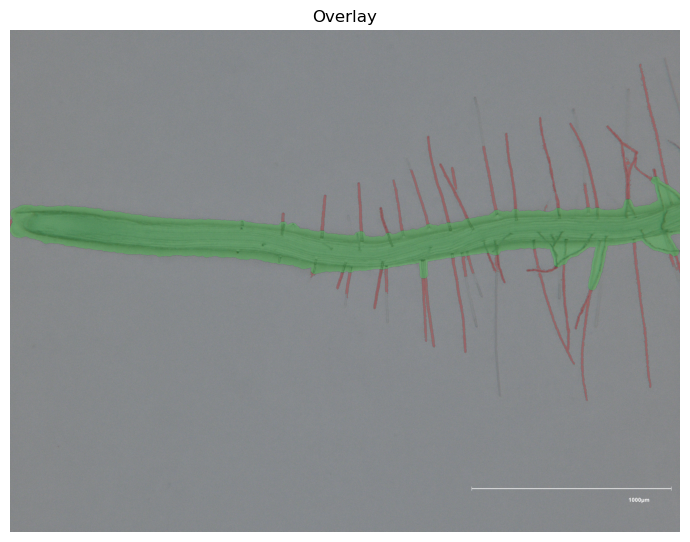

In [13]:
# Example run case

# Double roots
# image = "/home/mellanie/Desktop/Annotated_dataset/20241030_N4_Plate1_DAG6_1000_L/000010.tif"
# image = "/home/mellanie/Desktop/Annotated_dataset/20241030_N4_Plate1_DAG6_1000_L/000011.tif"


image = "/home/mellanie/Desktop/Annotated_dataset/20241002_N4_Plate1_DAG6_1000_L/000007.tif"
fused_classified_instances, model_instances, classic_masks = instance_segmentation_pipeline(image, verbose=False)

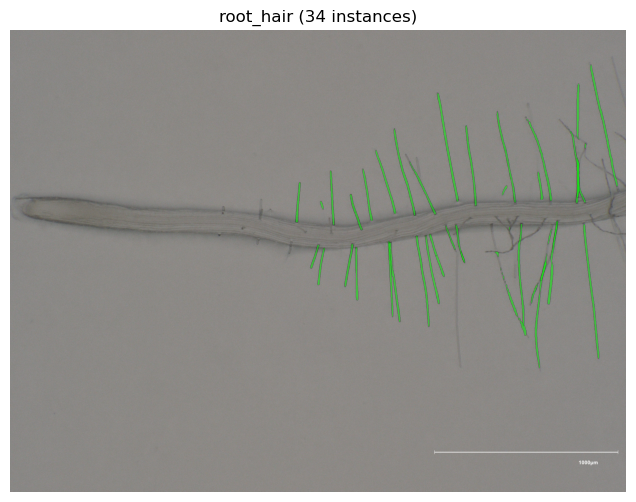

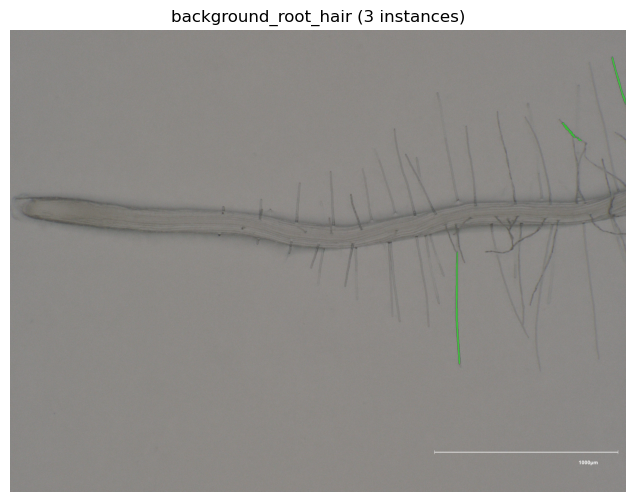

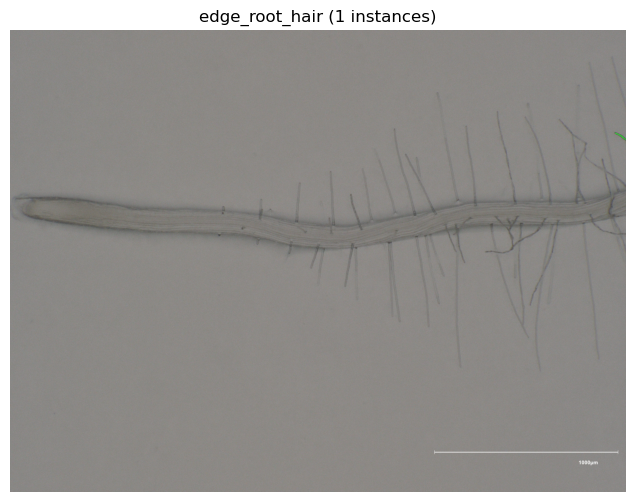

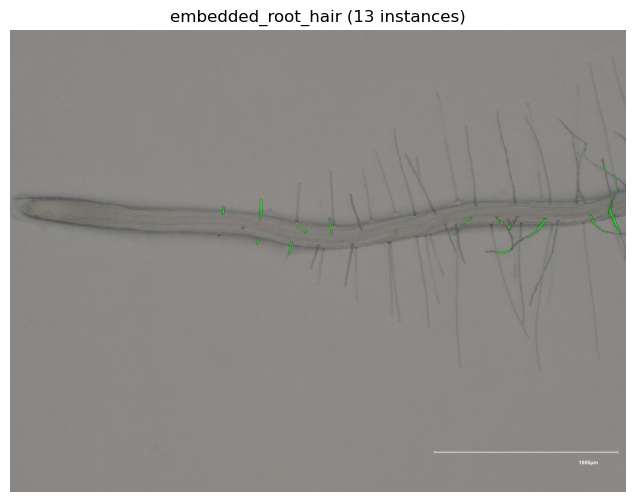

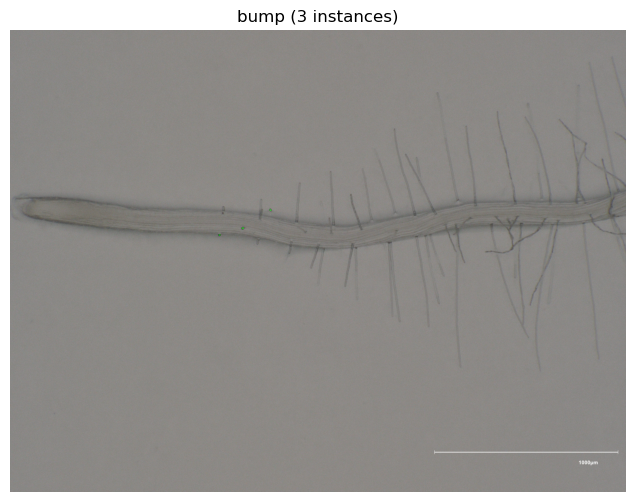

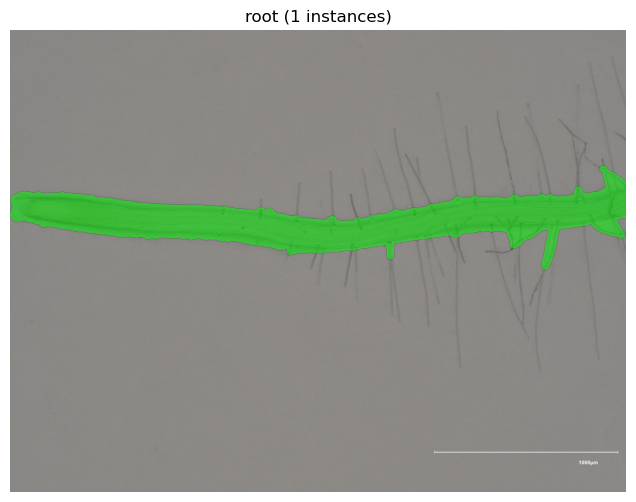

In [ ]:


image = cv2.imread(image)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Group masks by category
masks_by_category = defaultdict(list)
for instance in fused_classified_instances:
    masks_by_category[instance["category_id"]].append(instance["mask"])

# Plot one figure per category, with all its masks overlaid
for cat_id, mask_list in masks_by_category.items():
    cat_name = CLASSES[cat_id]
    
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.imshow(image)
    
    for mask in mask_list:
        overlay = np.zeros((*mask.shape, 4), dtype=np.uint8)
        overlay[mask] = (0, 255, 0, 128) 
        ax.imshow(overlay)
    
    ax.axis("off")
    ax.set_title(f"{cat_name} ({len(mask_list)} instances)")
    plt.show()